Score commercial auto policies for expected claim risk
Fits a model on historical data and scores the current period

Data:
train.csv  - policies 2020-2022, includes claim outcomes
score.csv  - policies 2023-2024, no outcomes (to be scored)

In [52]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import r_regression, f_regression, mutual_info_regression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
import seaborn as sns


In [48]:
pd.set_option('display.float_format', lambda x: '%.10f' % x)

In [20]:
# ---- load ----
df2 = pd.read_csv("../data/train.csv")
df3 = pd.read_csv("../data/score.csv")

print("train:", df2.shape)
print("score:", df3.shape)

train: (15075, 31)
score: (3000, 28)


In [21]:
# ---- preprocessing ----

# fill numeric missing with 0 -- good enough for now
df2[df2.select_dtypes("number").columns] = df2.select_dtypes("number").fillna(0)
df3[df3.select_dtypes("number").columns] = df3.select_dtypes("number").fillna(0)

# encode categoricals for train
df2["coverage_type"] = df2["coverage_type"].astype("category").cat.codes
df2["business_type"]  = df2["business_type"].astype("category").cat.codes
df2["state"]          = df2["state"].astype("category").cat.codes

# same for score
df3["coverage_type"] = df3["coverage_type"].astype("category").cat.codes
df3["business_type"]  = df3["business_type"].astype("category").cat.codes
df3["state"]          = df3["state"].astype("category").cat.codes

In [22]:
# ---- target ----
# using binary had-a-claim flag as target
df2["target"] = (df2["claim_count"] > 0).astype(int)
print("positive rate:", round(df2["target"].mean(), 3))

positive rate: 0.123


In [23]:
# ---- features ----
feat_cols = [
    "coverage_type",
    "vehicle_count", "vehicle_avg_age", "driver_count", "driver_avg_age",
    "years_in_business", "prior_year_mileage_000",
    "business_type", "state",
    "prior_apd_claim_count", "prior_al_claim_count", "prior_loss_amount",
    "deductible", "coverage_limit_000", "annual_premium",
    "risk_score_external", "num_heavy_vehicles", "late_payment_count",
    "claim_paid_amount_current_period",
    "days_to_first_claim_report",
]

X = df2[feat_cols]
y = df2["target"]

In [24]:
# ---- fit model ----

# random split -- not time-based
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

tmp = LogisticRegression(max_iter=1000)
tmp.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [25]:
# ---- evaluate ----
x1 = tmp.predict(X_test)
print("accuracy:", accuracy_score(y_test, x1))
# results look solid

accuracy: 1.0


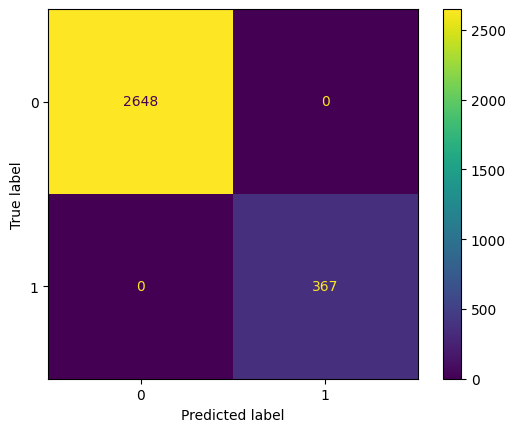

In [26]:
c_matrix = confusion_matrix(y_test, x1)
disp = ConfusionMatrixDisplay(confusion_matrix = c_matrix)
disp.plot()
plt.show()

In [28]:
print(classification_report(y_test, x1))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2648
           1       1.00      1.00      1.00       367

    accuracy                           1.00      3015
   macro avg       1.00      1.00      1.00      3015
weighted avg       1.00      1.00      1.00      3015



In [29]:
print(tmp.coef_)

[[-1.63013044e-05 -3.96523620e-04 -3.05549784e-04 -3.97669640e-04
  -2.70747503e-03 -5.35178263e-04 -7.81036277e-03 -4.87711787e-04
  -3.71712174e-04  2.38216147e-06 -1.05597042e-05 -4.68001217e-04
  -2.64654523e-03 -2.71604397e-02 -1.58149006e-03 -2.33950511e-03
  -9.53895110e-05 -3.70256781e-05  1.86052050e-01  4.09170558e-03]]


In [40]:
correlation_coefficients = r_regression(X_test, y_test)
correlation_df = pd.Series(correlation_coefficients, index=X_test.columns).sort_values(ascending=False)

print(correlation_df)

days_to_first_claim_report          0.987398
claim_paid_amount_current_period    0.287819
coverage_type                       0.113654
vehicle_count                       0.107044
prior_year_mileage_000              0.073439
prior_loss_amount                   0.070026
risk_score_external                 0.065222
num_heavy_vehicles                  0.062398
prior_apd_claim_count               0.054796
prior_al_claim_count                0.049819
driver_count                        0.013676
vehicle_avg_age                     0.013502
driver_avg_age                      0.011102
business_type                       0.006715
state                               0.004842
deductible                          0.004580
late_payment_count                 -0.005373
coverage_limit_000                 -0.008867
annual_premium                     -0.019636
years_in_business                  -0.036338
dtype: float64


In [49]:
f_statistic, p_values = f_regression(X_test, y_test)
regression_results = pd.DataFrame({
    'F-Score': f_statistic,
    'p-Value': p_values
}, index=X_test.columns)

regression_results = regression_results.sort_values(by='F-Score', ascending=False)

print(regression_results)

                                           F-Score      p-Value
days_to_first_claim_report       117285.9579609217 0.0000000000
claim_paid_amount_current_period    272.1407309956 0.0000000000
coverage_type                        39.4291370632 0.0000000004
vehicle_count                        34.9242713640 0.0000000038
prior_year_mileage_000               16.3382412111 0.0000543099
prior_loss_amount                    14.8474034536 0.0001189989
risk_score_external                  12.8718890685 0.0003388633
num_heavy_vehicles                   11.7768551797 0.0006077955
prior_apd_claim_count                 9.0739945321 0.0026142561
prior_al_claim_count                  7.4965325970 0.0062181218
years_in_business                     3.9837967120 0.0460297666
annual_premium                        1.1622288493 0.2810900769
driver_count                          0.5636284362 0.4528605998
vehicle_avg_age                       0.5493677728 0.4586338993
driver_avg_age                        0.

In [53]:
mir_coefficients = mutual_info_regression(X_test, y_test)

mir_df = pd.Series(mir_coefficients, index=X_test.columns).sort_values(ascending=False)

print(mir_df)

days_to_first_claim_report         0.3675972403
claim_paid_amount_current_period   0.3618959134
coverage_limit_000                 0.0306065791
vehicle_count                      0.0281434171
prior_al_claim_count               0.0178200813
num_heavy_vehicles                 0.0114920694
vehicle_avg_age                    0.0109313965
business_type                      0.0089376012
coverage_type                      0.0053006560
late_payment_count                 0.0014922994
state                              0.0011581877
driver_avg_age                     0.0008275640
driver_count                       0.0000000000
prior_apd_claim_count              0.0000000000
years_in_business                  0.0000000000
prior_year_mileage_000             0.0000000000
prior_loss_amount                  0.0000000000
risk_score_external                0.0000000000
deductible                         0.0000000000
annual_premium                     0.0000000000
dtype: float64


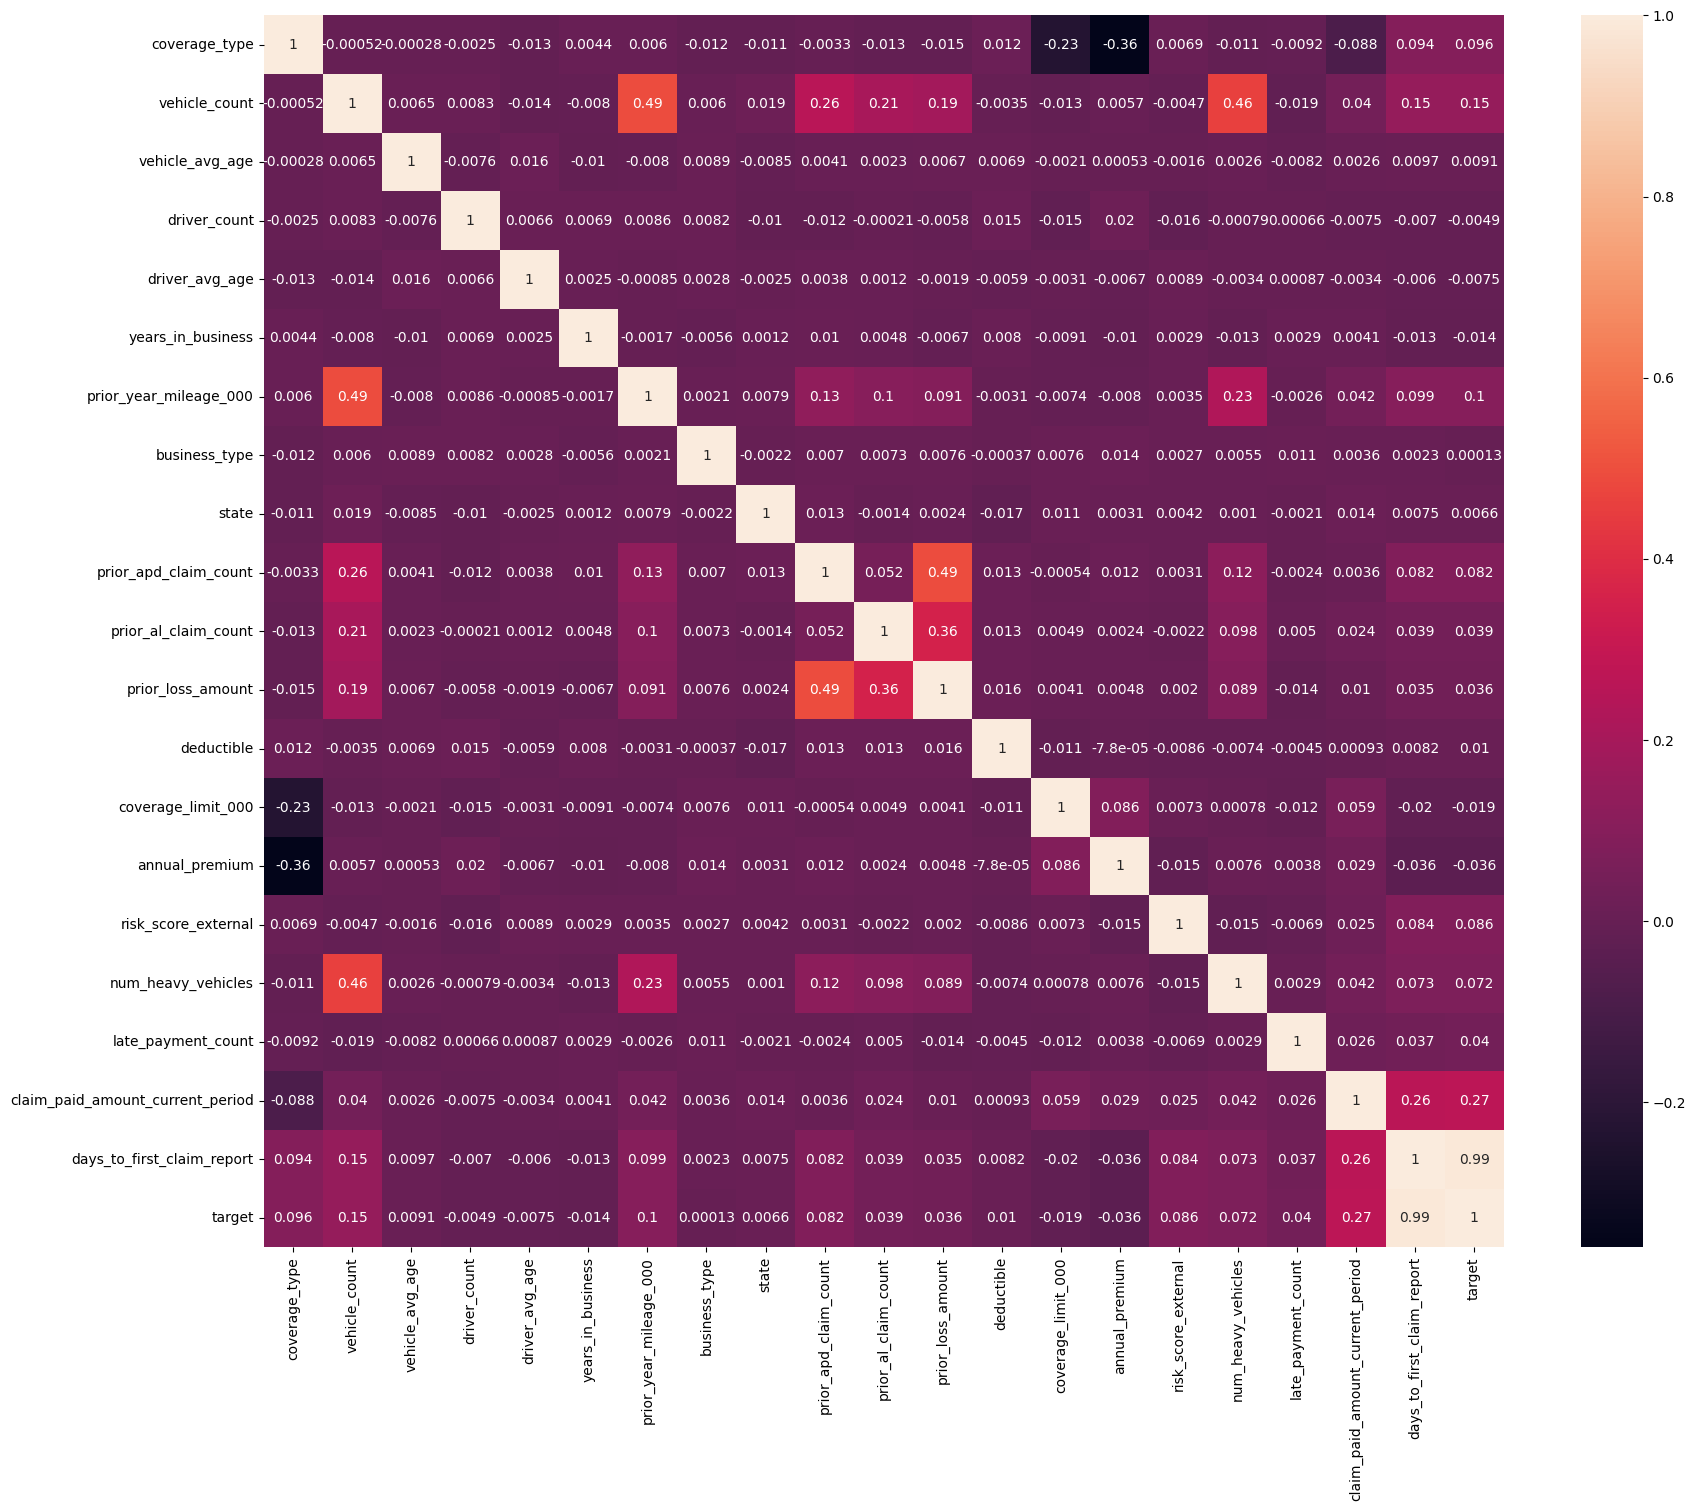

In [38]:
train_data = pd.concat([X_train, y_train], axis=1)

# correlation heatmap
plt.figure(figsize=(20, 16))
sns.heatmap(train_data.corr(), annot=True)
plt.show()

In [ ]:
# ---- score new policies ----
#X2 = df3[feat_cols]
#preds = tmp.predict(X2)

#df3["risk_score"] = preds
#df3[["policy_id", "risk_score"]].to_csv("predictions.csv")
#print("done -- predictions.csv written")

done -- predictions.csv written
